In [1]:
import pandas as pd
import numpy as np

# 设置随机种子，保证每次生成的数据都是一样的
np.random.seed(42)

# 生成 200 条模拟数据
data = {
    '受访者ID': range(1001, 1201),
    '省份': np.random.choice(['江苏省', '浙江省', '广东省', '四川省'], 200, p=[0.3, 0.3, 0.2, 0.2]),
    '性别': np.random.choice(['男', '女'], 200, p=[0.45, 0.55]),
    '年龄': np.random.randint(18, 65, 200),
    # 满意度打分（1-10分），故意设置江苏省稍微高一点，方便后面练习交叉分析
    '满意度': np.concatenate([
        np.random.randint(7, 11, 60), # 江苏省的数据 (60人)
        np.random.randint(5, 10, 60), # 浙江省的数据 (60人)
        np.random.randint(4, 9, 40),  # 广东省的数据 (40人)
        np.random.randint(3, 8, 40)   # 四川省的数据 (40人)
    ]),
    '是否为非遗爱好者': np.random.choice(['是', '否'], 200, p=[0.6, 0.4])
}

# 转换为 DataFrame
df = pd.DataFrame(data)

# 随机打乱一下顺序，模拟真实收集的数据
df = df.sample(frac=1).reset_index(drop=True)

# 我们人为制造一点点“脏数据”（缺失值），让你复习一下清洗，顺便看看 describe 怎么处理
df.loc[5:10, '年龄'] = np.nan
df.loc[15:20, '满意度'] = np.nan

print("✅ 数据生成成功！数据共有", len(df), "行。")
# 预览前 5 行
df.head()

✅ 数据生成成功！数据共有 200 行。


,受访者ID,省份,性别,年龄,满意度,是否为非遗爱好者
0,1068,四川省,女,24.0,9.0,是
1,1153,江苏省,女,63.0,7.0,是
2,1079,浙江省,女,27.0,9.0,是
3,1192,四川省,男,54.0,6.0,否
4,1188,浙江省,男,22.0,5.0,是


In [2]:
df.describe()

,受访者ID,年龄,满意度
count,200.000000,194.000000,194.000000
mean,1100.500000,40.649485,6.824742
std,57.879185,13.256373,1.780786
min,1001.000000,18.000000,3.000000
25%,1050.750000,29.250000,5.000000
50%,1100.500000,40.000000,7.000000
75%,1150.250000,52.000000,8.000000
max,1200.000000,64.000000,10.000000


In [3]:
df["性别"].value_counts()

性别
女    115
男     85
Name: count, dtype: int64

In [4]:
df["省份"].value_counts()

省份
江苏省    66
浙江省    56
四川省    42
广东省    36
Name: count, dtype: int64

In [5]:
df.groupby("省份")["满意度"].mean().sort_values(ascending=False)

省份
江苏省    7.031250
四川省    6.775000
广东省    6.722222
浙江省    6.685185
Name: 满意度, dtype: float64

In [6]:
df.groupby("性别")["满意度"].mean().sort_values(ascending=False)

性别
男    6.888889
女    6.778761
Name: 满意度, dtype: float64

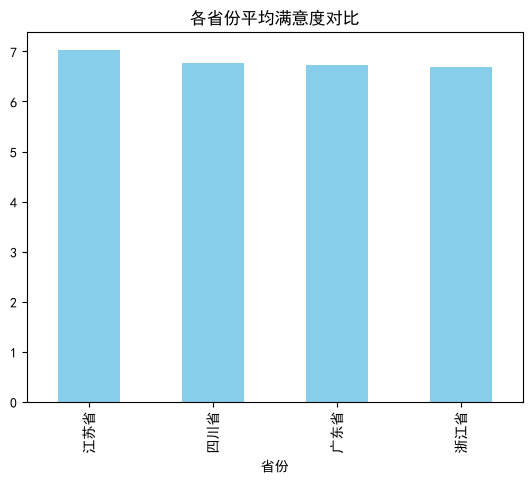

In [11]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
df.groupby("省份")["满意度"].mean().sort_values(ascending=False).plot(kind='bar',color='skyblue')
plt.title("各省份平均满意度对比")
plt.show()

ValueError: incomplete format

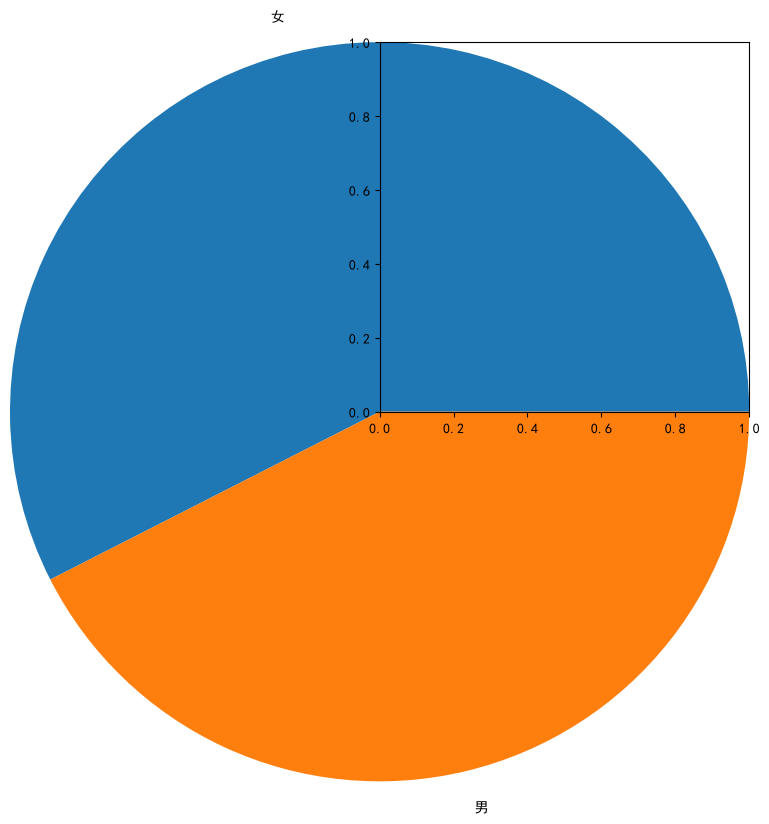

In [13]:
df["性别"].value_counts().plot(kind='pie',autopct='%1.1f%%',color=['lightcoral','lightskyblue'])
plt.title("受访者性别比例")
plt.ylabel('')
plt.show()